<a href="https://colab.research.google.com/github/tamarajovicic1/Data-Science-Masters/blob/main/covid-19-analysis/covid19_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Uvod

Cilj ovog projekta je da analiziramo podatke o pacijentima sa Covid-19 i predvidimo verovatnoću preživljavanja pacijenata koristeći različite tehnike mašinskog učenja. Očekivani rezultati uključuju identifikaciju ključnih faktora koji utiču na ishod bolesti i kreiranje modela koji može precizno predvideti ishod na osnovu tih faktora. Ova analiza može pomoći zdravstvenim radnicima da bolje razumeju faktore rizika i da optimizuju lečenje pacijenata.

## Prikupljanje podataka

Podaci korišćeni u ovom projektu su preuzeti sa sajta Kaggle, sa javno dostupnog skupa podataka o Covid-19 pacijentima. Ovi podaci uključuju informacije kao što su starost, pol, prisustvo komorbiditeta i drugi relevantni medicinski podaci. Podaci su dostupni na sledećem linku: [Covid-19 Dataset na Kaggle-u](https://www.kaggle.com/datasets/meirnizri/covid19-dataset). Ovi podaci su relevantni jer omogućavaju identifikaciju faktora koji utiču na ishod bolesti i omogućavaju obuku modela za predikciju preživljavanja.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('Covid Data.csv')
df.head()

,USMER,MEDICAL_UNIT,SEX,PATIENT_TYPE,DATE_DIED,INTUBED,PNEUMONIA,AGE,PREGNANT,DIABETES,...,ASTHMA,INMSUPR,HIPERTENSION,OTHER_DISEASE,CARDIOVASCULAR,OBESITY,RENAL_CHRONIC,TOBACCO,CLASIFFICATION_FINAL,ICU
0,2,1,1,1,03/05/2020,97,1,65,2,2,...,2,2,1,2,2,2,2,2,3,97
1,2,1,2,1,03/06/2020,97,1,72,97,2,...,2,2,1,2,2,1,1,2,5,97
2,2,1,2,2,09/06/2020,1,2,55,97,1,...,2,2,2,2,2,2,2,2,3,2
3,2,1,1,1,12/06/2020,97,2,53,2,2,...,2,2,2,2,2,2,2,2,7,97
4,2,1,2,1,21/06/2020,97,2,68,97,1,...,2,2,1,2,2,2,2,2,3,97


In [ ]:
# Zamena nevažećih datuma sa NaN vrednostima
df['DATE_DIED'].replace('99/99/9999', np.nan, inplace=True)

# Konvertovanje validnih datuma u datetime format
df['DATE_DIED'] = pd.to_datetime(df['DATE_DIED'], format='%d/%m/%Y', errors='coerce')

# Kreiranje kolone IS_ALIVE: 1 ako je DATE_DIED NaN, 0 inače
df['IS_ALIVE'] = df['DATE_DIED'].isna().astype(int)

df.head()

,USMER,MEDICAL_UNIT,SEX,PATIENT_TYPE,DATE_DIED,INTUBED,PNEUMONIA,AGE,PREGNANT,DIABETES,...,INMSUPR,HIPERTENSION,OTHER_DISEASE,CARDIOVASCULAR,OBESITY,RENAL_CHRONIC,TOBACCO,CLASIFFICATION_FINAL,ICU,IS_ALIVE
0,2,1,1,1,2020-05-03,97,1,65,2,2,...,2,1,2,2,2,2,2,3,97,0
1,2,1,2,1,2020-06-03,97,1,72,97,2,...,2,1,2,2,1,1,2,5,97,0
2,2,1,2,2,2020-06-09,1,2,55,97,1,...,2,2,2,2,2,2,2,3,2,0
3,2,1,1,1,2020-06-12,97,2,53,2,2,...,2,2,2,2,2,2,2,7,97,0
4,2,1,2,1,2020-06-21,97,2,68,97,1,...,2,1,2,2,2,2,2,3,97,0


In [ ]:
df = df.drop("DATE_DIED", axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 21 columns):
 #   Column                Non-Null Count    Dtype
---  ------                --------------    -----
 0   USMER                 1048575 non-null  int64
 1   MEDICAL_UNIT          1048575 non-null  int64
 2   SEX                   1048575 non-null  int64
 3   PATIENT_TYPE          1048575 non-null  int64
 4   INTUBED               1048575 non-null  int64
 5   PNEUMONIA             1048575 non-null  int64
 6   AGE                   1048575 non-null  int64
 7   PREGNANT              1048575 non-null  int64
 8   DIABETES              1048575 non-null  int64
 9   COPD                  1048575 non-null  int64
 10  ASTHMA                1048575 non-null  int64
 11  INMSUPR               1048575 non-null  int64
 12  HIPERTENSION          1048575 non-null  int64
 13  OTHER_DISEASE         1048575 non-null  int64
 14  CARDIOVASCULAR        1048575 non-null  int64
 15  OBESITY        

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Definisanje atributa X i ciljne promenljive y
X = df.drop(columns=['IS_ALIVE'])
y = df['IS_ALIVE']

# Podela podataka na skupove za obuku i testiranje
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardizacija podataka
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# Inicijalizacija modela
logreg = LogisticRegression()

# Treniranje modela
logreg.fit(X_train, y_train)

# Predviđanje rezultata
y_pred_logreg = logreg.predict(X_test)

# Evaluacija modela
print("Logistička regresija")
print("Tačnost (Accuracy):", accuracy_score(y_test, y_pred_logreg))
print("Izveštaj klasifikacije:\n", classification_report(y_test, y_pred_logreg))


Logistička regresija
Tačnost (Accuracy): 0.9361562120020027
Izveštaj klasifikacije:
               precision    recall  f1-score   support

           0       0.59      0.39      0.47     15240
           1       0.95      0.98      0.97    194475

    accuracy                           0.94    209715
   macro avg       0.77      0.69      0.72    209715
weighted avg       0.93      0.94      0.93    209715



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Inicijalizacija modela
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Treniranje modela
rf.fit(X_train, y_train)

# Predviđanje rezultata
y_pred_rf = rf.predict(X_test)

# Evaluacija modela
print("Random Forest Klasifikator")
print("Tačnost (Accuracy):", accuracy_score(y_test, y_pred_rf))
print("Izveštaj klasifikacije:\n", classification_report(y_test, y_pred_rf))

Random Forest Klasifikator
Tačnost (Accuracy): 0.944682068521565
Izveštaj klasifikacije:
               precision    recall  f1-score   support

           0       0.64      0.53      0.58     15240
           1       0.96      0.98      0.97    194475

    accuracy                           0.94    209715
   macro avg       0.80      0.76      0.78    209715
weighted avg       0.94      0.94      0.94    209715



In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Inicijalizacija modela
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)

# Treniranje modela
gb.fit(X_train, y_train)

# Predict
y_pred_gb = gb.predict(X_test)

# Evaluacija modela
print("Gradient Boosting Classifier")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Classification Report:\n", classification_report(y_test, y_pred_gb))

Gradient Boosting Classifier
Accuracy: 0.95152945664354
Classification Report:
               precision    recall  f1-score   support

           0       0.73      0.53      0.61     15240
           1       0.96      0.98      0.97    194475

    accuracy                           0.95    209715
   macro avg       0.85      0.76      0.79    209715
weighted avg       0.95      0.95      0.95    209715



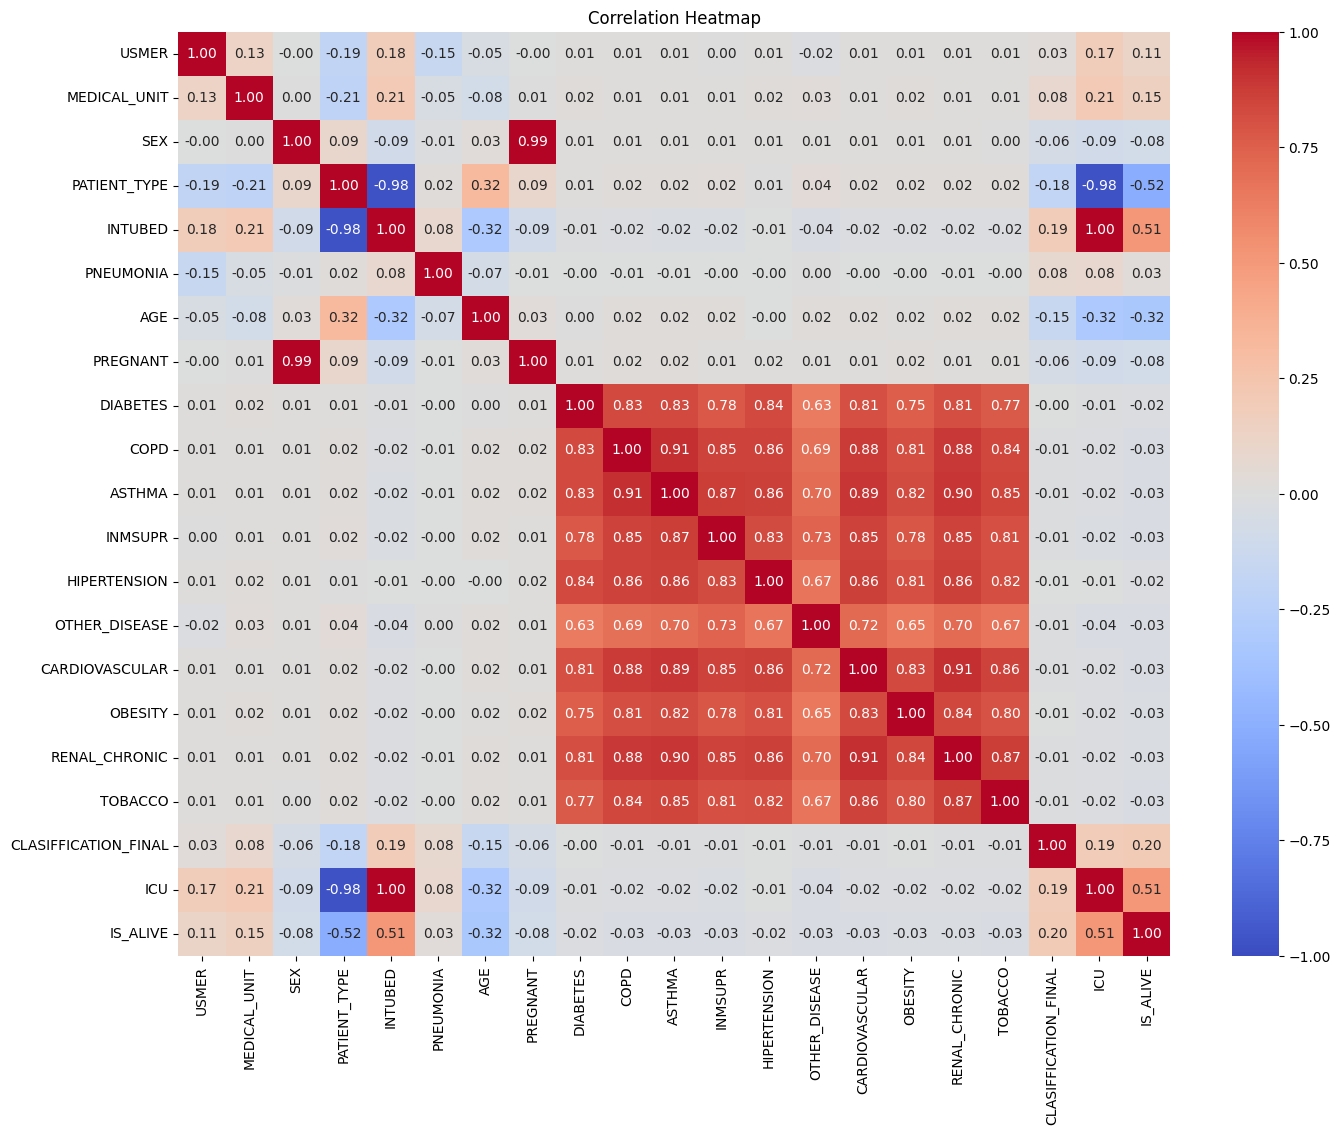

In [ ]:
# Izračunavanje matrice korelacije
corr_matrix = df.corr()

# Kreiranje heatmap-e
plt.figure(figsize=(16, 12))
heatmap = sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)

plt.title('Correlation Heatmap')

plt.show()

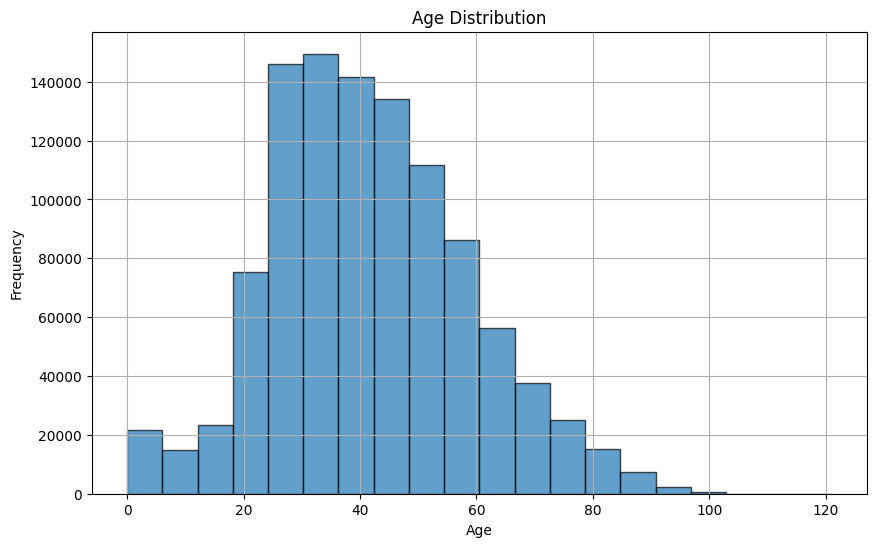

In [ ]:
# Histogram uzrasta
plt.figure(figsize=(10, 6))
plt.hist(df['AGE'], bins=20, edgecolor='black', alpha=0.7)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()


## Zaključak

Kroz analizu podataka o pacijentima sa Covid-19, koristili smo nekoliko algoritama mašinskog učenja kako bismo predvideli verovatnoću preživljavanja pacijenata. Najbolje performanse postigao je model Gradient Boosting Classifier, sa visokom tačnošću i preciznim predviđanjima. Prednosti ove metode uključuju njenu sposobnost da identifikuje složene obrasce u podacima, dok su njeni nedostaci veće vreme obučavanja i potreba za većim resursima.

Moguća unapređenja uključuju testiranje dodatnih algoritama, uključivanje više podataka za trening, kao i finije podešavanje hiperparametara modela. Buduće primene mogu uključivati integraciju ovih modela u sistem za podršku odlučivanju u zdravstvenim ustanovama, čime bi se poboljšala tačnost i brzina donošenja kliničkih odluka.